# Importing the libraries

In [5]:
import cv2 as cv
import numpy as np
import seaborn as sn
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# Importing the dataset

In [6]:
(x_train, y_train), (x_temp, y_temp) = tf.keras.datasets.cifar10.load_data()

In [7]:
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Previewing the dataset

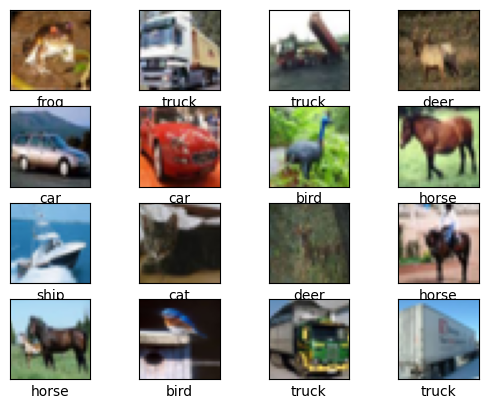

In [8]:
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(x_train[i])
    plt.xlabel(classes[y_train[i][0]])
plt.show()

# Test and validation dataset

In [5]:
x_test, x_valid = np.split(x_temp, 2)
y_test, y_valid = np.split(y_temp, 2)

# Scaling the dataset

In [6]:
x_train, x_test, x_valid = x_train / 255, x_test / 255, x_valid / 255

# building the model

In [7]:
model = tf.keras.models.Sequential()

In [8]:
model.add(tf.keras.layers.Conv2D(32, (3, 3), activation = 'relu', padding = 'same', strides = (1, 1), input_shape = (32, 32, 3)))
model.add(tf.keras.layers.MaxPooling2D((2, 2)))
model.add(tf.keras.layers.Conv2D(64, (3, 3), activation = 'relu', padding = 'same', strides = (1, 1)))
model.add(tf.keras.layers.MaxPooling2D((2, 2)))
model.add(tf.keras.layers.Conv2D(128, (3, 3), activation = 'relu', padding = 'same', strides = (1, 1)))
model.add(tf.keras.layers.MaxPooling2D((2, 2)))
model.add(tf.keras.layers.Conv2D(256, (3, 3), activation = 'relu', padding = 'same', strides = (1, 1)))
model.add(tf.keras.layers.MaxPooling2D((2, 2)))
model.add(tf.keras.layers.Conv2D(512, (3, 3), activation = 'relu', padding = 'same', strides = (1, 1)))
model.add(tf.keras.layers.MaxPooling2D((2, 2)))
model.add(tf.keras.layers.Flatten())
model.add(tf.keras.layers.Dense(512, activation = 'relu'))
model.add(tf.keras.layers.Dense(256, activation = 'relu'))
model.add(tf.keras.layers.Dense(128, activation = 'relu'))
model.add(tf.keras.layers.Dense(64, activation = 'relu'))
model.add(tf.keras.layers.Dense(32, activation = 'relu'))
model.add(tf.keras.layers.Dense(10, activation = 'softmax'))

In [9]:
model.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy', metrics = 'accuracy')

# training the model

In [10]:
history = model.fit(x_train, y_train, batch_size = 32, epochs = 20, validation_data = (x_valid, y_valid))

Epoch 1/20
1563/1563 [==============================] - 214s 136ms/step - loss: 1.7990 - accuracy: 0.2952 - val_loss: 1.4726 - val_accuracy: 0.4426
Epoch 2/20
1563/1563 [==============================] - 210s 134ms/step - loss: 1.2980 - accuracy: 0.5222 - val_loss: 1.2614 - val_accuracy: 0.5426
Epoch 3/20
1563/1563 [==============================] - 205s 131ms/step - loss: 1.0641 - accuracy: 0.6198 - val_loss: 1.0678 - val_accuracy: 0.6262
Epoch 4/20
1563/1563 [==============================] - 206s 132ms/step - loss: 0.9188 - accuracy: 0.6758 - val_loss: 0.9436 - val_accuracy: 0.6706
Epoch 5/20
1563/1563 [==============================] - 277s 177ms/step - loss: 0.8217 - accuracy: 0.7144 - val_loss: 0.9426 - val_accuracy: 0.6818
Epoch 6/20
1563/1563 [==============================] - 218s 140ms/step - loss: 0.7390 - accuracy: 0.7441 - val_loss: 0.9077 - val_accuracy: 0.6994
Epoch 7/20
1563/1563 [==============================] - 212s 136ms/step - loss: 0.6718 - accuracy: 0.7680 - val_

# Evaluating the model

In [11]:
print(model.evaluate(x_test, y_test))

157/157 [==============================] - 3s 19ms/step - loss: 1.2841 - accuracy: 0.7300
[1.2841145992279053, 0.7300000190734863]


In [12]:
predictions = model.predict(x_test)

157/157 [==============================] - 3s 19ms/step


In [13]:
y_pred = [np.argmax(i) for i in predictions]
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.79      0.78      0.79       488
           1       0.88      0.84      0.86       505
           2       0.61      0.68      0.64       512
           3       0.54      0.48      0.51       497
           4       0.67      0.67      0.67       507
           5       0.60      0.61      0.61       488
           6       0.77      0.80      0.78       491
           7       0.74      0.79      0.76       495
           8       0.89      0.84      0.87       504
           9       0.82      0.79      0.81       513

    accuracy                           0.73      5000
   macro avg       0.73      0.73      0.73      5000
weighted avg       0.73      0.73      0.73      5000



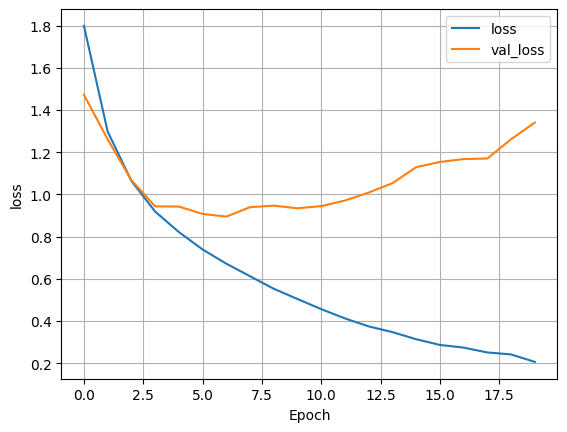

In [14]:
plt.plot(history.history['loss'], label = 'loss')
plt.plot(history.history['val_loss'], label = 'val_loss')
plt.ylabel("loss")
plt.xlabel("Epoch")
plt.grid('true')
plt.legend()
plt.show()

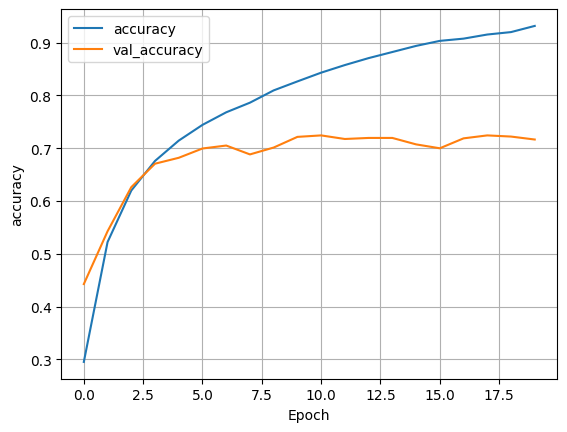

In [15]:
plt.plot(history.history['accuracy'], label = 'accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.ylabel("accuracy")
plt.xlabel("Epoch")
plt.grid('true')
plt.legend()
plt.show()

In [16]:
cm = tf.math.confusion_matrix(labels = y_test, predictions = y_pred)

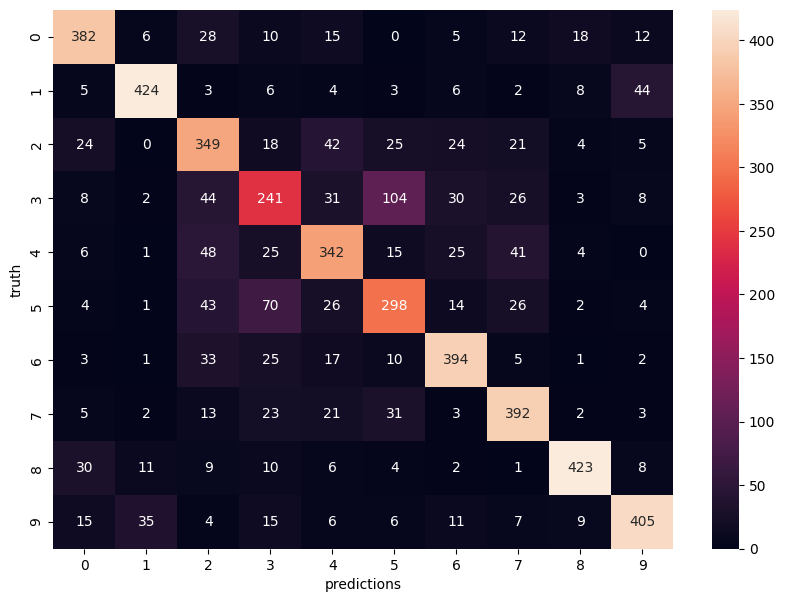

In [17]:
plt.figure(figsize = (10, 7))
sn.heatmap(cm, annot = True, fmt = 'd')
plt.xlabel('predictions')
plt.ylabel('truth')
plt.show()

# Making a prediction

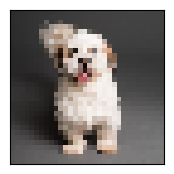

In [18]:
img = cv.imread('../images/dog.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
img = cv.resize(img, (32, 32))
plt.figure(figsize = (15, 2))
plt.xticks([])
plt.yticks([])
plt.imshow(img)
plt.show()

In [19]:
prediction = model.predict(np.array([img]) / 255)
print("prediction:",classes[np.argmax(prediction)])

1/1 [==============================] - 0s 26ms/step
prediction: dog


In [20]:
model.save('../models/finalimageclassifier.keras')